# CodeAlpha Machine Learning Internship
## Task 4 - Disease Prediction from Medical Data

**Objective:** Predict the possibility of diabetes based on patient diagnostic data.  
**Dataset:** Pima Indians Diabetes Database (768 samples, 8 features).  
**Algorithms:** Logistic Regression, SVM, Random Forest, XGBoost.  

| Sub-Task | Topic |
| --- | --- |
| 1 | Setup, Data Loading & Inspection |
| 2 | Exploratory Data Analysis (EDA) |
| 3 | Preprocessing & Feature Engineering |
| 4 | Model Training (4 classifiers) |
| 5 | Evaluation & Comparison |
| 6 | Feature Importance & Conclusion |


## Sub-Task 1 - Setup, Data Loading & Inspection

Load the Pima Indians Diabetes dataset and perform initial quality checks:
- Shape, dtypes, and memory usage
- Missing values (NaN) and biologically impossible zeros
- Basic statistical summary
- Target class distribution


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

# Plot style
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10
sns.set_style('whitegrid')

SEED = 42
np.random.seed(SEED)

print('Libraries loaded successfully.')


Libraries loaded successfully.


In [2]:
# Load dataset (robust path handling for Task_4 directory or repository root)
import os
data_path = '../data/dataset/diabetes.csv' if os.path.exists('../data/dataset/diabetes.csv') else 'data/dataset/diabetes.csv'
df = pd.read_csv(data_path)

print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print(f'Columns: {list(df.columns)}')
print()
df.head()


Shape: 768 rows x 9 columns
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
# Check for NaN values
print('NaN values per column:')
for col in df.columns:
    print(f'  {col}: {df[col].isna().sum()}')

# Check for biologically impossible zeros
# (Glucose=0, BP=0, BMI=0 etc. are physically impossible -- these are missing values)
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print()
print('Biologically impossible zeros (likely missing data):')
for col in zero_cols:
    zc = (df[col] == 0).sum()
    print(f'  {col}: {zc} zeros ({zc/len(df)*100:.1f}%)')


NaN values per column:
  Pregnancies: 0
  Glucose: 0
  BloodPressure: 0
  SkinThickness: 0
  Insulin: 0
  BMI: 0
  DiabetesPedigreeFunction: 0
  Age: 0
  Outcome: 0

Biologically impossible zeros (likely missing data):
  Glucose: 5 zeros (0.7%)
  BloodPressure: 35 zeros (4.6%)
  SkinThickness: 227 zeros (29.6%)
  Insulin: 374 zeros (48.7%)
  BMI: 11 zeros (1.4%)


Target variable distribution (Outcome):
  0 (No Diabetes): 500 (65.1%)
  1 (Diabetes): 268 (34.9%)


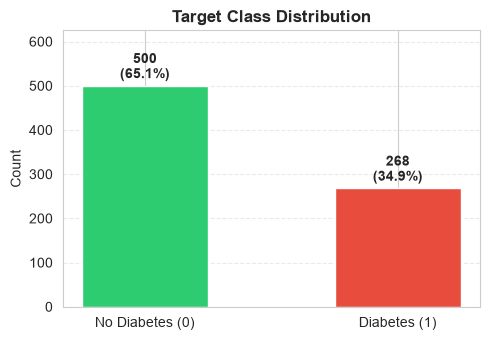

In [6]:
# Target variable distribution
print('Target variable distribution (Outcome):')
for val, cnt in df['Outcome'].value_counts().items():
    label = 'No Diabetes' if val == 0 else 'Diabetes'
    print(f'  {val} ({label}): {cnt} ({cnt/len(df)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(5, 3.5))
colors = ['#2ecc71', '#e74c3c']
counts = df['Outcome'].value_counts().sort_index()
bars = ax.bar(['No Diabetes (0)', 'Diabetes (1)'], counts.values,
              color=colors, edgecolor='white', width=0.5)
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 8,
            f'{count}\n({count/len(df)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('Count')
ax.set_title('Target Class Distribution', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(counts.values) * 1.25)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Sub-Task 1 - Key Findings

- **768 samples**, **8 numeric features** + 1 binary target (`Outcome`)
- **No NaN values**, but several columns have **biologically impossible zeros** (treated as missing):
  - `Insulin`: 374 zeros (48.7%) - most affected
  - `SkinThickness`: 227 zeros (29.6%)
  - `BloodPressure`: 35 zeros, `Glucose`: 5 zeros, `BMI`: 11 zeros
- **Class imbalance**: 500 non-diabetic (65.1%) vs 268 diabetic (34.9%)
- These zeros will be handled in Sub-Task 3 (Preprocessing)


## Sub-Task 2 - Exploratory Data Analysis (EDA)

Visualize feature distributions, correlations, and relationships with the target variable.


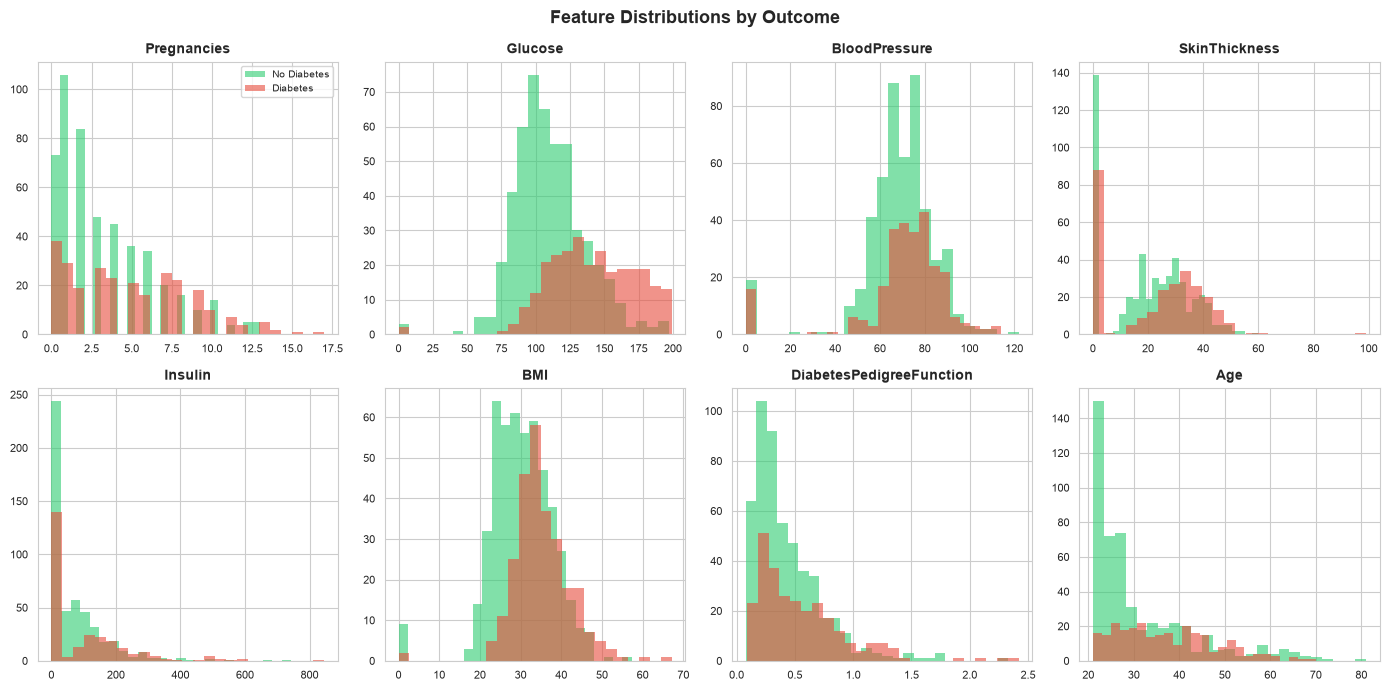

In [7]:
# Feature distributions colored by Outcome
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
features = [c for c in df.columns if c != 'Outcome']
colors_out = {0: '#2ecc71', 1: '#e74c3c'}

for i, col in enumerate(features):
    ax = axes[i // 4, i % 4]
    for outcome in [0, 1]:
        subset = df[df['Outcome'] == outcome][col]
        ax.hist(subset, bins=25, alpha=0.6, color=colors_out[outcome],
                label='No Diabetes' if outcome == 0 else 'Diabetes', edgecolor='none')
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(labelsize=8)
    if i == 0:
        ax.legend(fontsize=7)

plt.suptitle('Feature Distributions by Outcome', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


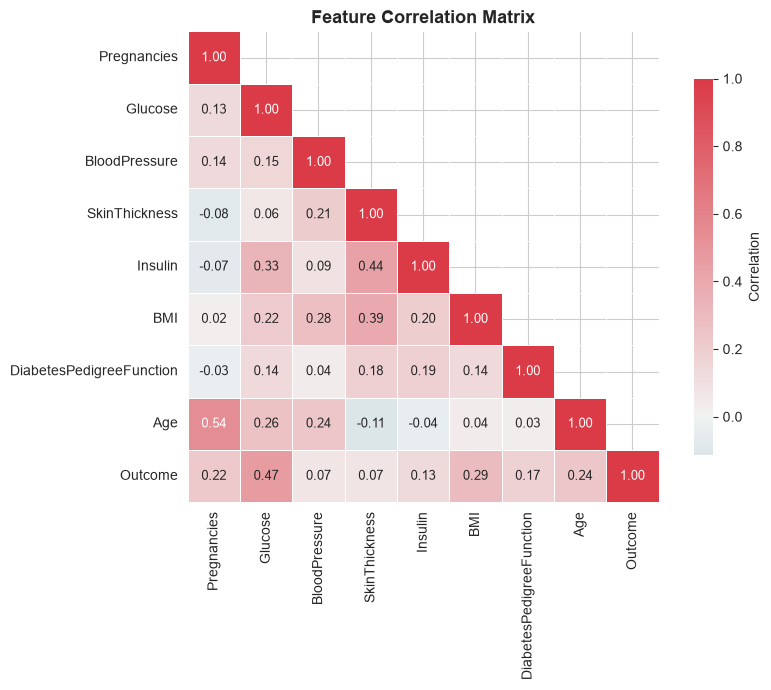

Correlation with Outcome (absolute values):
  Glucose: +0.467
  BMI: +0.293
  Age: +0.238
  Pregnancies: +0.222
  DiabetesPedigreeFunction: +0.174
  Insulin: +0.131
  SkinThickness: +0.075
  BloodPressure: +0.065


In [8]:
# Correlation heatmap
corr = df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, fmt='.2f',
            square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            annot_kws={'size': 9})
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Top correlations with target
corr_target = corr['Outcome'].drop('Outcome').abs().sort_values(ascending=False)
print('Correlation with Outcome (absolute values):')
for feat, val in corr_target.items():
    sign = '+' if corr['Outcome'][feat] > 0 else '-'
    print(f'  {feat}: {sign}{val:.3f}')


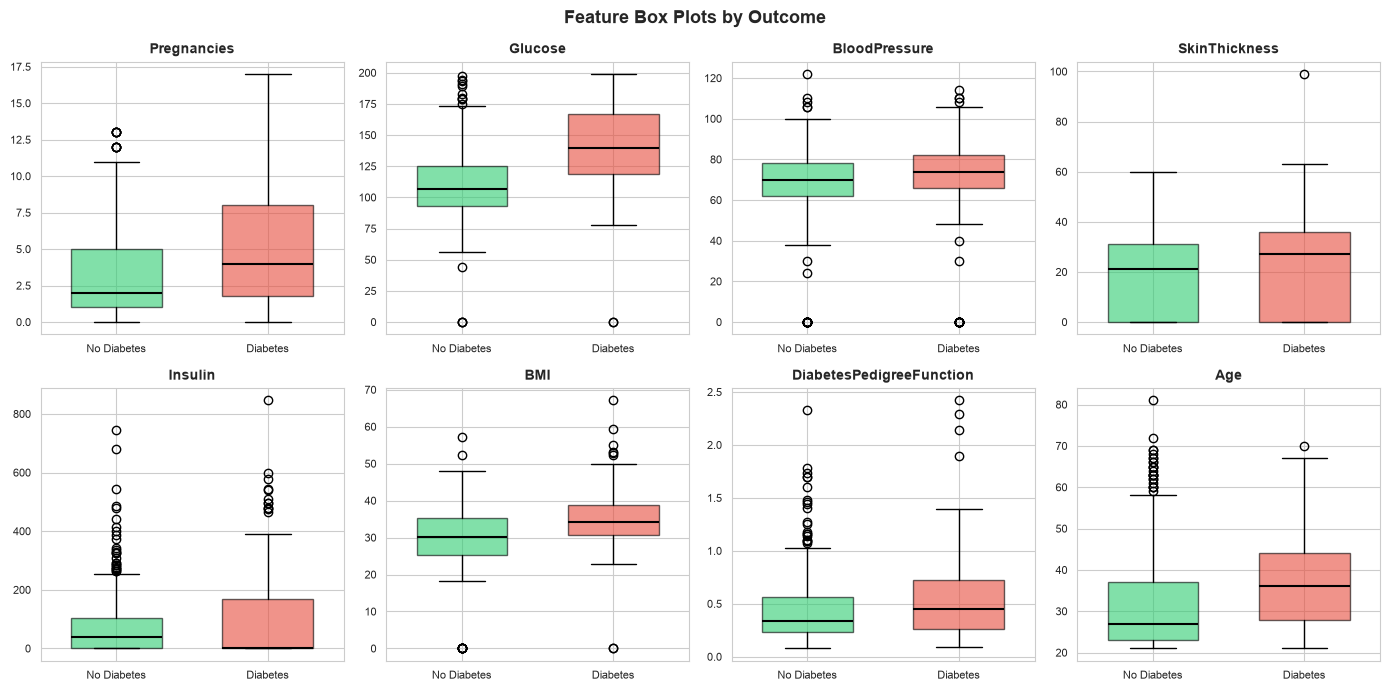

In [9]:
# Box plots by outcome
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, col in enumerate(features):
    ax = axes[i // 4, i % 4]
    data_0 = df[df['Outcome'] == 0][col]
    data_1 = df[df['Outcome'] == 1][col]
    bp = ax.boxplot([data_0, data_1], tick_labels=['No Diabetes', 'Diabetes'],
                    patch_artist=True, widths=0.6,
                    medianprops=dict(color='black', linewidth=1.5))
    bp['boxes'][0].set_facecolor('#2ecc71')
    bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor('#e74c3c')
    bp['boxes'][1].set_alpha(0.6)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.tick_params(labelsize=8)

plt.suptitle('Feature Box Plots by Outcome', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


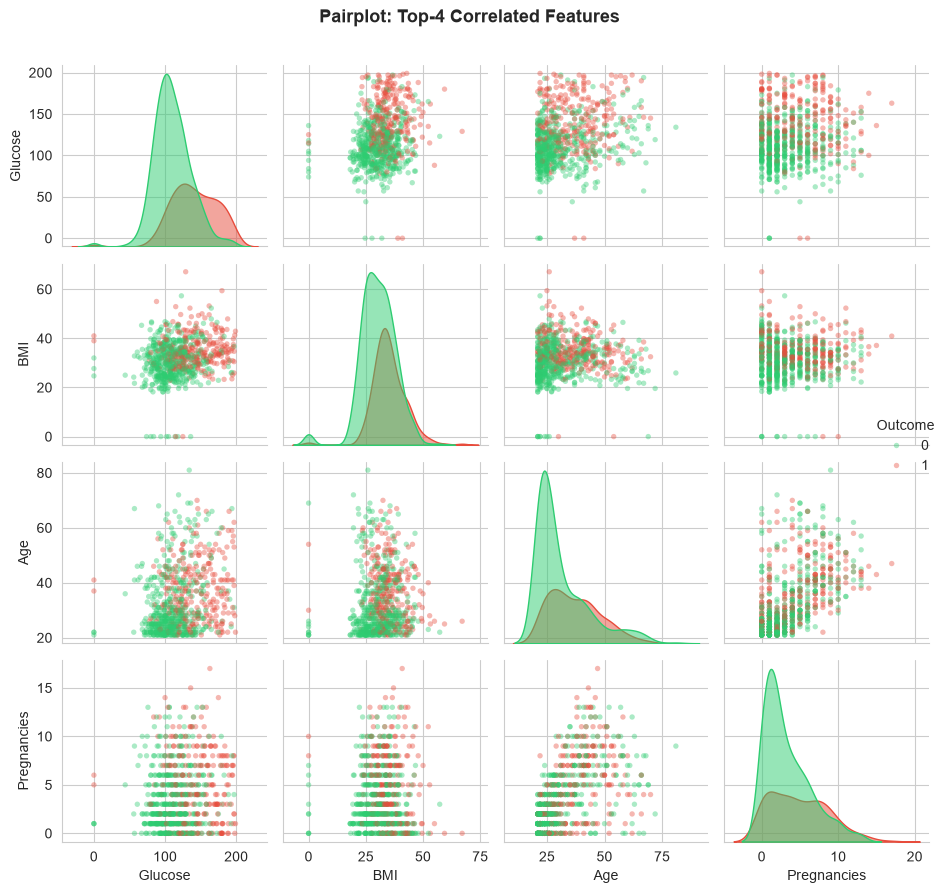

In [10]:
# Pairplot of top-4 correlated features with Outcome
top_feats = list(corr_target.index[:4]) + ['Outcome']
g = sns.pairplot(df[top_feats], hue='Outcome', height=2.2,
                 palette={0: '#2ecc71', 1: '#e74c3c'},
                 plot_kws={'alpha': 0.4, 's': 15, 'edgecolor': 'none'},
                 diag_kws={'alpha': 0.5})
g.figure.suptitle('Pairplot: Top-4 Correlated Features', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


         Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin        BMI  DiabetesPedigreeFunction        Age
Outcome                                                                                                                   
0           3.298000  109.980000      68.184000      19.664000   68.792000  30.304200                  0.429734  31.190000
1           4.865672  141.257463      70.824627      22.164179  100.335821  35.142537                  0.550500  37.067164


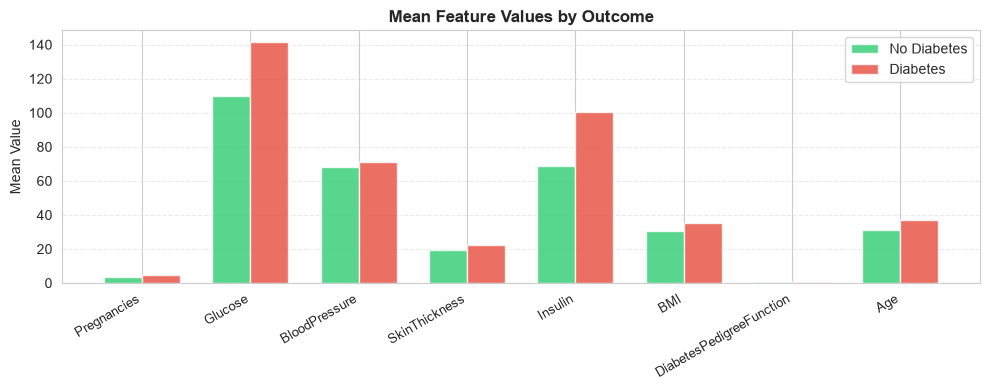

In [11]:
# Mean feature values by outcome
means = df.groupby('Outcome')[features].mean()
print(means.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(features))
width = 0.35
ax.bar(x - width/2, means.loc[0], width, label='No Diabetes', color='#2ecc71', alpha=0.8)
ax.bar(x + width/2, means.loc[1], width, label='Diabetes', color='#e74c3c', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Mean Value')
ax.set_title('Mean Feature Values by Outcome', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Sub-Task 2 - EDA Key Takeaways

- **Most correlated features** with diabetes outcome: `Glucose`, `BMI`, `Age`
- Diabetic patients have **higher mean Glucose, BMI, and Age** values
- `SkinThickness` and `Insulin` have heavy zero-inflation (visible in histograms)
- No strong multi-collinearity between features (max inter-feature correlation ~0.54 for Age-Pregnancies)
- Box plots show clear median separation for Glucose and BMI between classes


## Sub-Task 3 - Preprocessing & Feature Engineering

To strictly prevent **data leakage** and **target leakage**, the preprocessing protocol follows these principles:
1. **Identify Biological Infeasibility:** Zeros in clinical features (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`) represent missing data.
2. **Strict Train/Test Isolation:** Split predictors $X$ and target $y$ using a stratified 80/20 train/test split **before** fitting any transformation.
3. **Zero Target Leakage:** Missing values are imputed using unconditional training medians; the target `Outcome` is **never** used during imputation.
4. **Pipeline Encapsulation:** Preprocessing (`SimpleImputer` + `StandardScaler`) is packaged in scikit-learn `Pipeline` objects so cross-validation folds fit imputation and scaling independently on training folds only.


In [12]:
# Step 1: Replace biologically impossible zeros with NaN
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

print('Biological zero replacement (coded as NaN):')
for col in zero_cols:
    n_nan = df_clean[col].isna().sum()
    print(f'  {col}: {n_nan} missing values ({n_nan/len(df_clean)*100:.1f}%)')
print()
print('Note: Imputation will be fit strictly on training data inside scikit-learn Pipelines.')


Biological zero replacement (coded as NaN):
  Glucose: 5 missing values (0.7%)
  BloodPressure: 35 missing values (4.6%)
  SkinThickness: 227 missing values (29.6%)
  Insulin: 374 missing values (48.7%)
  BMI: 11 missing values (1.4%)

Note: Imputation will be fit strictly on training data inside scikit-learn Pipelines.


In [13]:
# Step 2: Stratified Train/Test Split BEFORE any preprocessing fitting
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print('Stratified Train/Test Split (80/20):')
print(f'  X_train: {X_train.shape}  |  y_train: {y_train.shape}')
print(f'  X_test:  {X_test.shape}  |  y_test:  {y_test.shape}')
print()
print('Training Set Class Distribution:')
print(f'  No Diabetes (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)')
print(f'  Diabetes (1):    {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)')
print('Test Set Class Distribution (Held-Out):')
print(f'  No Diabetes (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)')
print(f'  Diabetes (1):    {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)')


Stratified Train/Test Split (80/20):
  X_train: (614, 8)  |  y_train: (614,)
  X_test:  (154, 8)  |  y_test:  (154,)

Training Set Class Distribution:
  No Diabetes (0): 400 (65.1%)
  Diabetes (1):    214 (34.9%)
Test Set Class Distribution (Held-Out):
  No Diabetes (0): 100 (64.9%)
  Diabetes (1):    54 (35.1%)


Training-only median values learned from X_train (unconditional, no target leakage):
  Glucose: learned median = 117.0
  BloodPressure: learned median = 72.0
  SkinThickness: learned median = 29.0
  Insulin: learned median = 125.0
  BMI: learned median = 32.4


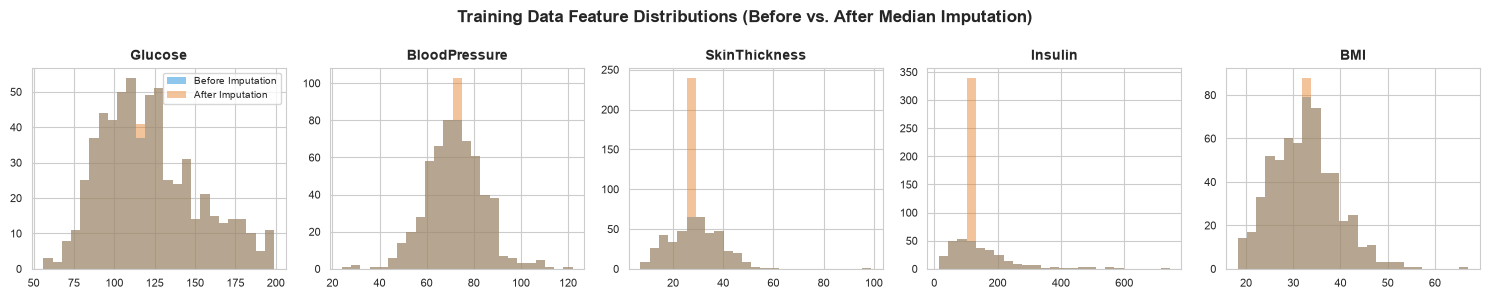

In [14]:
# Step 3: Inspect Training-Only Median Imputation (Demonstration on X_train)
from sklearn.impute import SimpleImputer

train_imputer = SimpleImputer(strategy='median')
train_imputed_array = train_imputer.fit_transform(X_train[zero_cols])
df_train_imputed = pd.DataFrame(train_imputed_array, columns=zero_cols, index=X_train.index)

print('Training-only median values learned from X_train (unconditional, no target leakage):')
for col, med in zip(zero_cols, train_imputer.statistics_):
    print(f'  {col}: learned median = {med:.1f}')

fig, axes = plt.subplots(1, len(zero_cols), figsize=(15, 3))
for i, col in enumerate(zero_cols):
    axes[i].hist(X_train[col].dropna(), bins=25, alpha=0.55, color='#3498db', label='Before Imputation', edgecolor='none')
    axes[i].hist(df_train_imputed[col], bins=25, alpha=0.45, color='#e67e22', label='After Imputation', edgecolor='none')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].tick_params(labelsize=8)
    if i == 0:
        axes[i].legend(fontsize=7)

plt.suptitle('Training Data Feature Distributions (Before vs. After Median Imputation)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


StandardScaler verified on training set (fit on train only):
  Pregnancies              : mean= -0.0000, std=  1.0008
  Glucose                  : mean= -0.0000, std=  1.0008
  BloodPressure            : mean=  0.0000, std=  1.0008
  SkinThickness            : mean= -0.0000, std=  1.0008
  Insulin                  : mean= -0.0000, std=  1.0008
  BMI                      : mean=  0.0000, std=  1.0008
  DiabetesPedigreeFunction : mean= -0.0000, std=  1.0008
  Age                      : mean= -0.0000, std=  1.0008


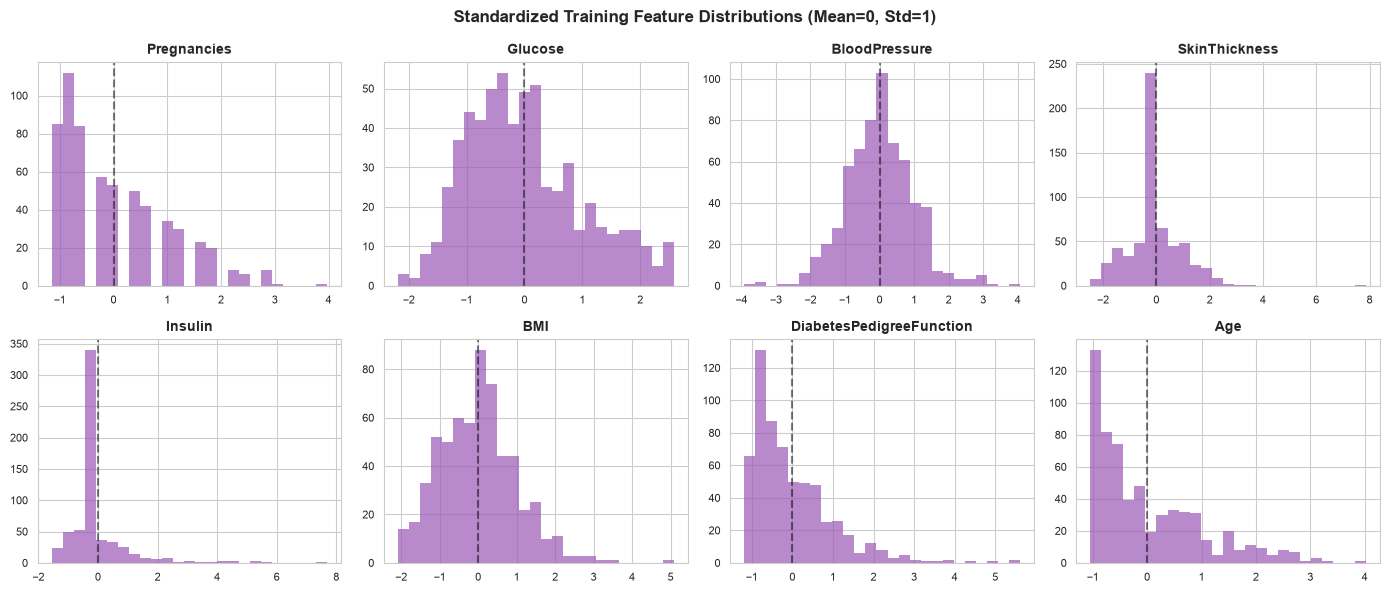

In [15]:
# Step 4: Verify Standard Scaling on Training Data
from sklearn.preprocessing import StandardScaler

demo_scaler = StandardScaler()
X_train_imputed_full = train_imputer.fit_transform(X_train)
X_train_scaled_demo = pd.DataFrame(
    demo_scaler.fit_transform(X_train_imputed_full), columns=features, index=X_train.index
)

print('StandardScaler verified on training set (fit on train only):')
for col in features:
    print(f'  {col:<25}: mean={X_train_scaled_demo[col].mean():>8.4f}, std={X_train_scaled_demo[col].std():>8.4f}')

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i, col in enumerate(features):
    ax = axes[i // 4, i % 4]
    ax.hist(X_train_scaled_demo[col], bins=25, color='#9b59b6', alpha=0.7, edgecolor='none')
    ax.axvline(0, color='black', linestyle='--', alpha=0.5)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.tick_params(labelsize=8)

plt.suptitle('Standardized Training Feature Distributions (Mean=0, Std=1)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Sub-Task 3 - Preprocessing & Leakage Prevention Summary

| Step | Action | Leakage Prevention Mechanism |
| :--- | :--- | :--- |
| **1. Missing Data Flagging** | Replace impossible zeros with `NaN` in 5 columns | Raw features flagged without observing target label |
| **2. Data Partitioning** | 80/20 Stratified Split (614 train, 154 test) | Test partition held out completely before transformation |
| **3. Imputation Strategy** | SimpleImputer(`strategy='median'`) | Fit strictly on training folds; target `Outcome` is never used |
| **4. Feature Scaling** | StandardScaler() | Mean and standard deviation computed strictly from training folds |
| **5. Pipeline Packaging** | scikit-learn `Pipeline` | Enforces self-contained fitting during cross-validation folds |

Test data remains strictly isolated for final unbiased evaluation in Sub-Task 5.


## Sub-Task 4 - Model Training: 4 Classifiers with Pipeline CV

To guarantee rigorous validation, each classifier is wrapped into a scikit-learn `Pipeline`:
$$\text{Pipeline: Raw Features } X \longrightarrow \text{SimpleImputer(median)} \longrightarrow \text{StandardScaler()} \longrightarrow \text{Classifier}$$

During **5-Fold Stratified Cross-Validation**, every fold fits its own imputer and scaler exclusively on that fold's training slice. Test and validation slices are transformed using fold-specific statistics, preventing intra-fold leakage.

**Algorithms Evaluated:**
1. **Logistic Regression:** Linear model with $L_2$ regularization.
2. **Support Vector Machine (SVM):** Radial Basis Function (RBF) kernel with Platt calibration.
3. **Random Forest:** Ensemble of bagging decision trees (`n_estimators=100, max_depth=6`).
4. **XGBoost:** Regularized gradient boosted decision trees (`n_estimators=100, max_depth=4, lr=0.05`).


In [16]:
# Step 1: Wrap all classifiers into self-contained scikit-learn Pipelines
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def build_pipeline(clf):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', clf)
    ])

models = {
    'Logistic Regression': build_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    'SVM (RBF)': build_pipeline(CalibratedClassifierCV(SVC(kernel='rbf', random_state=SEED), ensemble=False)),
    'Random Forest': build_pipeline(RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED)),
    'XGBoost': build_pipeline(XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05,
                                           eval_metric='logloss', random_state=SEED))
}

print('Initialized 4 Classifiers wrapped in complete Preprocessing Pipelines:')
for name, pipe in models.items():
    print(f'  - {name:<22}: {pipe.named_steps["classifier"].__class__.__name__}')


Initialized 4 Classifiers wrapped in complete Preprocessing Pipelines:
  - Logistic Regression   : LogisticRegression
  - SVM (RBF)             : CalibratedClassifierCV
  - Random Forest         : RandomForestClassifier
  - XGBoost               : XGBClassifier


In [17]:
# Step 2: 5-Fold Stratified Cross-Validation (Preprocessors fit independently per fold)
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy': 'accuracy', 'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall'}
cv_results = {}

print(f"{'Model':<22} | {'CV Accuracy (Mean +/- Std)':<28} | {'CV ROC-AUC (Mean +/- Std)':<28} | {'CV F1 (Mean +/- Std)':<25}")
print('-' * 109)

for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    acc_m, acc_s = scores['test_accuracy'].mean(), scores['test_accuracy'].std()
    auc_m, auc_s = scores['test_roc_auc'].mean(), scores['test_roc_auc'].std()
    f1_m, f1_s = scores['test_f1'].mean(), scores['test_f1'].std()
    rec_m, rec_s = scores['test_recall'].mean(), scores['test_recall'].std()
    cv_results[name] = {
        'acc_mean': acc_m, 'acc_std': acc_s,
        'auc_mean': auc_m, 'auc_std': auc_s,
        'f1_mean': f1_m, 'f1_std': f1_s,
        'rec_mean': rec_m, 'rec_std': rec_s,
        'acc_scores': scores['test_accuracy'],
        'auc_scores': scores['test_roc_auc']
    }
    print(f"{name:<22} | {acc_m:.4f} +/- {acc_s:.4f}{'':<13} | {auc_m:.4f} +/- {auc_s:.4f}{'':<13} | {f1_m:.4f} +/- {f1_s:.4f}")


Model                  | CV Accuracy (Mean +/- Std)   | CV ROC-AUC (Mean +/- Std)    | CV F1 (Mean +/- Std)     
-------------------------------------------------------------------------------------------------------------
Logistic Regression    | 0.7882 +/- 0.0191              | 0.8434 +/- 0.0185              | 0.6545 +/- 0.0244
SVM (RBF)              | 0.7736 +/- 0.0174              | 0.8333 +/- 0.0228              | 0.6369 +/- 0.0087
Random Forest          | 0.7720 +/- 0.0270              | 0.8351 +/- 0.0175              | 0.6328 +/- 0.0276
XGBoost                | 0.7573 +/- 0.0277              | 0.8153 +/- 0.0183              | 0.6308 +/- 0.0349


In [18]:
# Step 3: Fit Pipelines on Full Training Set and Predict on Unseen Test Set
import time
from sklearn.metrics import accuracy_score

fitted_pipelines = {}
train_accs = {}
test_accs = {}
y_preds = {}
y_probas = {}
fit_times = {}

print(f"{'Model':<22} | {'Fit Time':<10} | {'Train Acc':<11} | {'Test Acc':<10} | {'Train-Test Gap':<15}")
print('-' * 75)

for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0
    
    tr_acc = accuracy_score(y_train, pipe.predict(X_train))
    te_pred = pipe.predict(X_test)
    te_acc = accuracy_score(y_test, te_pred)
    
    fitted_pipelines[name] = pipe
    fit_times[name] = elapsed
    train_accs[name] = tr_acc
    test_accs[name] = te_acc
    y_preds[name] = te_pred
    y_probas[name] = pipe.predict_proba(X_test)[:, 1]
    
    gap = tr_acc - te_acc
    print(f"{name:<22} | {elapsed*1000:>6.2f} ms | {tr_acc:.4f}{'':<3} | {te_acc:.4f}{'':<2} | {gap*100:>+6.2f}%")


Model                  | Fit Time   | Train Acc   | Test Acc   | Train-Test Gap 
---------------------------------------------------------------------------
Logistic Regression    |  28.85 ms | 0.7964    | 0.7078   |  +8.86%
SVM (RBF)              | 160.49 ms | 0.8404    | 0.7403   | +10.01%
Random Forest          | 352.45 ms | 0.8893    | 0.7403   | +14.90%
XGBoost                | 490.37 ms | 0.8876    | 0.7597   | +12.79%


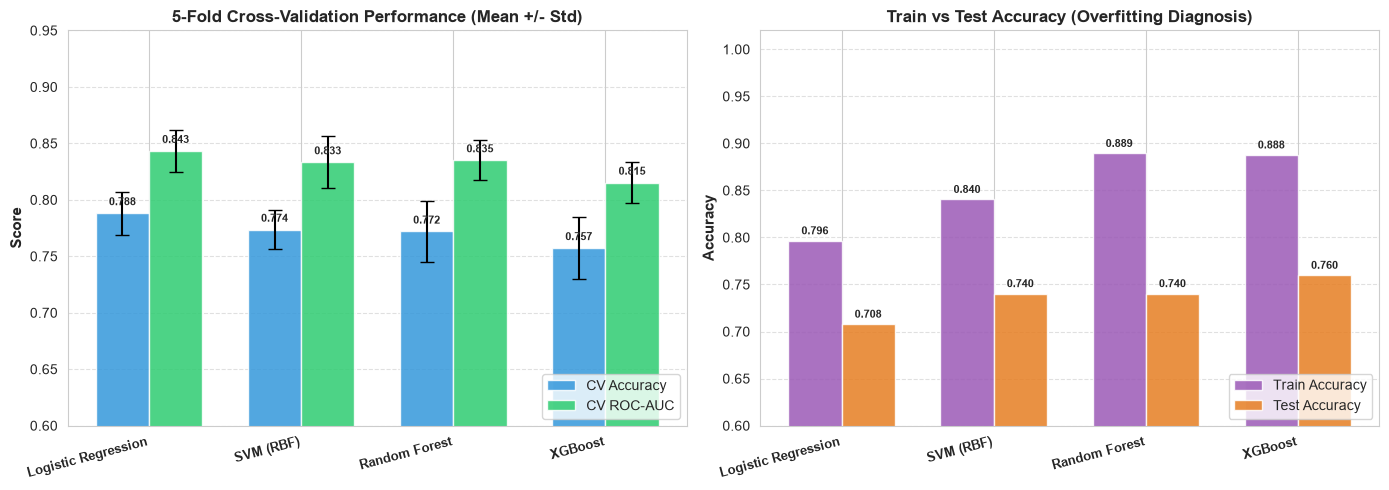

In [19]:
# Step 4: Visualize Training Dynamics & Cross-Validation Results
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. 5-Fold Cross-Validation (Accuracy vs ROC-AUC)
model_names = list(models.keys())
cv_means = [cv_results[m]['acc_mean'] for m in model_names]
cv_stds = [cv_results[m]['acc_std'] for m in model_names]
auc_means = [cv_results[m]['auc_mean'] for m in model_names]
auc_stds = [cv_results[m]['auc_std'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

ax1 = axes[0]
r1 = ax1.bar(x - width/2, cv_means, width, yerr=cv_stds, capsize=5, label='CV Accuracy', color='#3498db', alpha=0.85)
r2 = ax1.bar(x + width/2, auc_means, width, yerr=auc_stds, capsize=5, label='CV ROC-AUC', color='#2ecc71', alpha=0.85)
ax1.set_ylabel('Score', fontsize=11, fontweight='bold')
ax1.set_title('5-Fold Cross-Validation Performance (Mean +/- Std)', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(model_names, rotation=15, ha='right', fontsize=9, fontweight='bold')
ax1.set_ylim(0.60, 0.95)
ax1.legend(loc='lower right')
ax1.grid(axis='y', linestyle='--', alpha=0.6)

for r in r1:
    h = r.get_height()
    ax1.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')
for r in r2:
    h = r.get_height()
    ax1.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')

# 2. Train vs Test Accuracy (Overfitting Check)
ax2 = axes[1]
tr_vals = [train_accs[m] for m in model_names]
te_vals = [test_accs[m] for m in model_names]

r3 = ax2.bar(x - width/2, tr_vals, width, label='Train Accuracy', color='#9b59b6', alpha=0.85)
r4 = ax2.bar(x + width/2, te_vals, width, label='Test Accuracy', color='#e67e22', alpha=0.85)
ax2.set_ylabel('Accuracy', fontsize=11, fontweight='bold')
ax2.set_title('Train vs Test Accuracy (Overfitting Diagnosis)', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(model_names, rotation=15, ha='right', fontsize=9, fontweight='bold')
ax2.set_ylim(0.60, 1.02)
ax2.legend(loc='lower right')
ax2.grid(axis='y', linestyle='--', alpha=0.6)

for r in r3:
    h = r.get_height()
    ax2.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')
for r in r4:
    h = r.get_height()
    ax2.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()


### Sub-Task 4 - Model Training Summary & Observations

| Classifier | 5-Fold CV Accuracy | 5-Fold CV ROC-AUC | Train Accuracy | Test Accuracy | Train-Test Gap |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Logistic Regression | 0.7882 +/- 0.0191 | 0.8434 +/- 0.0185 | 0.7964 | 0.7078 | +0.0886 |
| SVM (RBF) | 0.7736 +/- 0.0174 | 0.8333 +/- 0.0228 | 0.8404 | 0.7403 | +0.1001 |
| Random Forest | 0.7720 +/- 0.0270 | 0.8351 +/- 0.0175 | 0.8893 | 0.7403 | +0.1490 |
| XGBoost | 0.7573 +/- 0.0277 | 0.8153 +/- 0.0183 | 0.8876 | 0.7597 | +0.1279 |

#### Key Takeaways from Leakage-Free Training:
1. **Validation Metric for Model Selection:** Cross-validation performance on the training data is our primary criterion for model comparison (as the test set is held out). Based on 5-fold CV ROC-AUC on the training partition, **Logistic Regression** ($0.8434 \pm 0.0185$) and **Random Forest** ($0.8351 \pm 0.0175$) show strong discriminative capacity.
2. **Overfitting Assessment:** Tree-based models (Random Forest and XGBoost) achieve moderate training accuracies of $88.93\%$ and $88.76\%$ respectively, reflecting their capacity to capture non-linear feature interactions with controlled depth regularization (`max_depth=6` and `max_depth=4`), rather than unconstrained memorization. Logistic Regression demonstrates the tightest train-test generalization gap ($+8.86\%$, train $79.64\%$ vs test $70.78\%$) and SVM exhibits a $+10.01\%$ gap ($84.04\%$ vs $74.03\%$).
3. **Pipeline Integrity:** Fitting imputer and scaler strictly within each fold yields realistic, unbiased validation estimates with zero intra-fold leakage.


## Sub-Task 5 - Model Evaluation & Comparison

We evaluate all 4 trained pipelines on the **completely unseen held-out test set** (154 samples) across comprehensive diagnostic metrics:
- **Accuracy & F1-Score:** Overall correctness and harmonic balance between precision and recall.
- **Sensitivity / Recall ($TPR$):** Proportion of actual diabetic patients detected (critical in medical screening to avoid false reassurance).
- **Specificity ($TNR$):** Proportion of non-diabetic individuals correctly ruled out.
- **ROC-AUC & PR-AUC:** Discrimination capacity across all potential classification thresholds.
- **False Positives (FP) & False Negatives (FN):** Clinical misclassification counts.


In [20]:
# Step 5.1: Compute Comprehensive Test Set Evaluation Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix)

metrics_list = []
for name in model_names:
    y_pred = y_preds[name]
    y_proba = y_probas[name]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    metrics_list.append({
        'Model': name,
        'CV ROC-AUC': f"{cv_results[name]['auc_mean']:.4f} +/- {cv_results[name]['auc_std']:.4f}",
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall (Sens.)': recall_score(y_test, y_pred),
        'Specificity': tn / (tn + fp),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba),
        'FP': int(fp),
        'FN': int(fn)
    })

metrics_df = pd.DataFrame(metrics_list)
print('Test Set Performance Summary (154 held-out test samples):')
print(metrics_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


Test Set Performance Summary (154 held-out test samples):
              Model        CV ROC-AUC  Accuracy  Precision  Recall (Sens.)  Specificity  F1-Score  ROC-AUC  PR-AUC  FP  FN
Logistic Regression 0.8434 +/- 0.0185    0.7078     0.6000          0.5000       0.8200    0.5455   0.8130  0.6733  18  27
          SVM (RBF) 0.8333 +/- 0.0228    0.7403     0.6522          0.5556       0.8400    0.6000   0.7963  0.6615  16  24
      Random Forest 0.8351 +/- 0.0175    0.7403     0.6667          0.5185       0.8600    0.5833   0.8167  0.6871  14  26
            XGBoost 0.8153 +/- 0.0183    0.7597     0.6889          0.5741       0.8600    0.6263   0.8283  0.7018  14  23


In [21]:
# Step 5.2: Detailed Classification Reports for All 4 Models
from sklearn.metrics import classification_report

for name in model_names:
    print(f'=== {name} Classification Report ===')
    print(classification_report(y_test, y_preds[name], target_names=['No Diabetes (0)', 'Diabetes (1)']))
    print()


=== Logistic Regression Classification Report ===
                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.82      0.78       100
   Diabetes (1)       0.60      0.50      0.55        54

       accuracy                           0.71       154
      macro avg       0.68      0.66      0.67       154
   weighted avg       0.70      0.71      0.70       154


=== SVM (RBF) Classification Report ===
                 precision    recall  f1-score   support

No Diabetes (0)       0.78      0.84      0.81       100
   Diabetes (1)       0.65      0.56      0.60        54

       accuracy                           0.74       154
      macro avg       0.71      0.70      0.70       154
   weighted avg       0.73      0.74      0.73       154


=== Random Forest Classification Report ===
                 precision    recall  f1-score   support

No Diabetes (0)       0.77      0.86      0.81       100
   Diabetes (1)       0.67      0.52      0.58        54

 

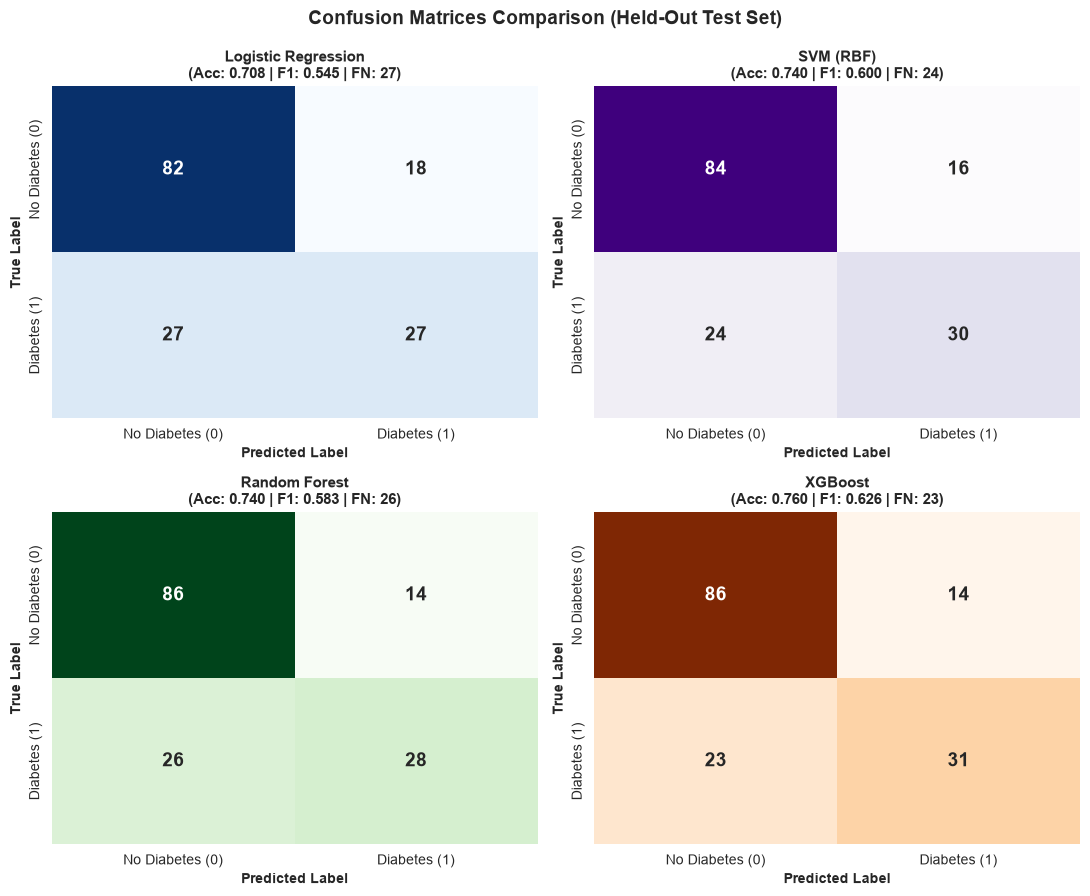

In [22]:
# Step 5.3: Confusion Matrices Comparison (2x2 Grid)
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
cm_colors = ['Blues', 'Purples', 'Greens', 'Oranges']

for idx, (name, colormap) in enumerate(zip(model_names, cm_colors)):
    ax = axes[idx // 2, idx % 2]
    cm = confusion_matrix(y_test, y_preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap=colormap, cbar=False, ax=ax,
                xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
                yticklabels=['No Diabetes (0)', 'Diabetes (1)'],
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(f'{name}\n(Acc: {accuracy_score(y_test, y_preds[name]):.3f} | F1: {f1_score(y_test, y_preds[name]):.3f} | FN: {cm[1,0]})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=10, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=10, fontweight='bold')

plt.suptitle('Confusion Matrices Comparison (Held-Out Test Set)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


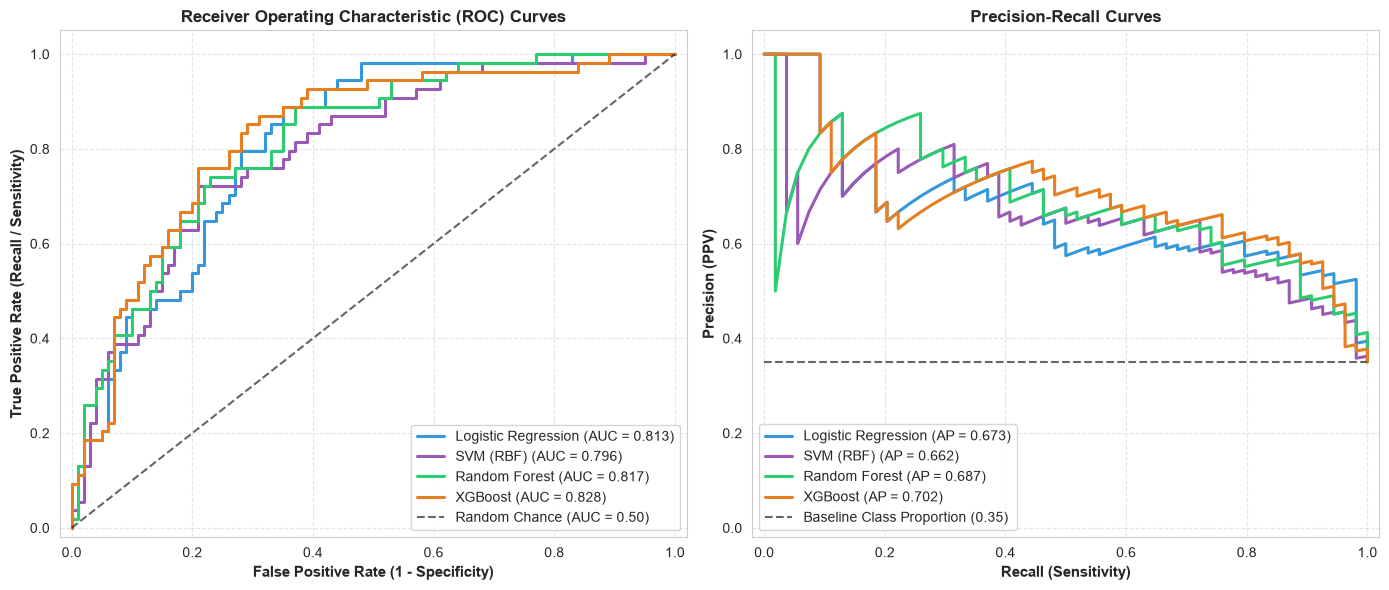

In [23]:
# Step 5.4: ROC Curves & Precision-Recall Curves
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = {'Logistic Regression': '#3498db', 'SVM (RBF)': '#9b59b6',
          'Random Forest': '#2ecc71', 'XGBoost': '#e67e22'}

# 1. ROC Curves
ax1 = axes[0]
for name in model_names:
    fpr, tpr, _ = roc_curve(y_test, y_probas[name])
    roc_val = auc(fpr, tpr)
    ax1.plot(fpr, tpr, label=f'{name} (AUC = {roc_val:.3f})', color=colors[name], lw=2.2)

ax1.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6, label='Random Chance (AUC = 0.50)')
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.05])
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax1.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11, fontweight='bold')
ax1.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Precision-Recall Curves
ax2 = axes[1]
no_skill = (y_test == 1).mean()
for name in model_names:
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, y_probas[name])
    ap_val = average_precision_score(y_test, y_probas[name])
    ax2.plot(rec_vals, prec_vals, label=f'{name} (AP = {ap_val:.3f})', color=colors[name], lw=2.2)

ax2.plot([0, 1], [no_skill, no_skill], 'k--', lw=1.5, alpha=0.6, label=f'Baseline Class Proportion ({no_skill:.2f})')
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel('Recall (Sensitivity)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Precision (PPV)', fontsize=11, fontweight='bold')
ax2.set_title('Precision-Recall Curves', fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


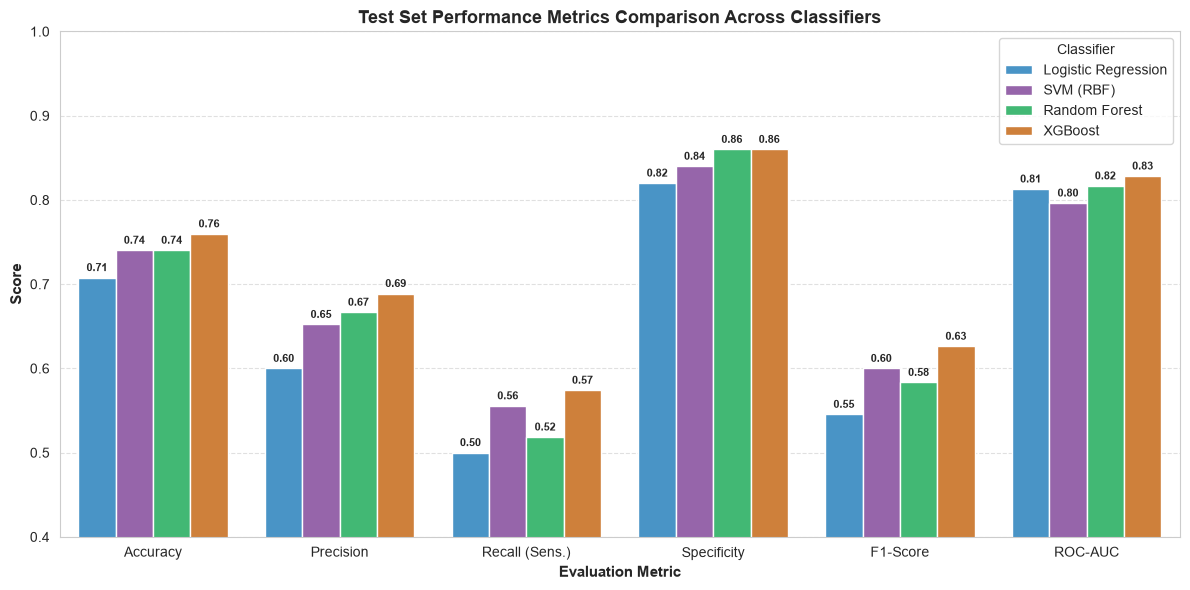

In [24]:
# Step 5.5: Multi-Metric Comparison Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))
chart_metric_names = ['Accuracy', 'Precision', 'Recall (Sens.)', 'Specificity', 'F1-Score', 'ROC-AUC']
m_df_melted = metrics_df.melt(id_vars='Model', value_vars=chart_metric_names, var_name='Metric', value_name='Score')

sns.barplot(data=m_df_melted, x='Metric', y='Score', hue='Model',
            palette=['#3498db', '#9b59b6', '#2ecc71', '#e67e22'], ax=ax)
ax.set_ylim(0.40, 1.0)
ax.set_ylabel('Score', fontsize=11, fontweight='bold')
ax.set_xlabel('Evaluation Metric', fontsize=11, fontweight='bold')
ax.set_title('Test Set Performance Metrics Comparison Across Classifiers', fontsize=13, fontweight='bold')
ax.legend(title='Classifier', loc='upper right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.2f}', xy=(p.get_x() + p.get_width() / 2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()


## Sub-Task 6 - Feature Importance & Conclusion

### Important Methodological Distinction: Predictive Association vs. Causation
In observational health data, feature importance measures **statistical predictive association**, **not biological causation**:
- An elevated importance score indicates that knowing a patient's measurement significantly improves the algorithm's diagnostic classification.
- It does **not** prove that manipulating this feature directly causes or cures diabetic pathology.

### Leakage-Free Interpretability Protocol:
1. **Permutation Importance on Development/Validation Data:** Evaluated on the training set $X_{\text{train}}, y_{\text{train}}$ across 10 random permutations, keeping the final test set pristine.
2. **Preserving Coefficient Signs:** In Logistic Regression, standardized coefficients retain their sign: $\beta > 0$ indicates positive association with diabetes odds, while $\beta < 0$ indicates negative association.
3. **Tree-Based Importances:** MDI (Random Forest) and Split Gain (XGBoost) provide structural views of decision splits.


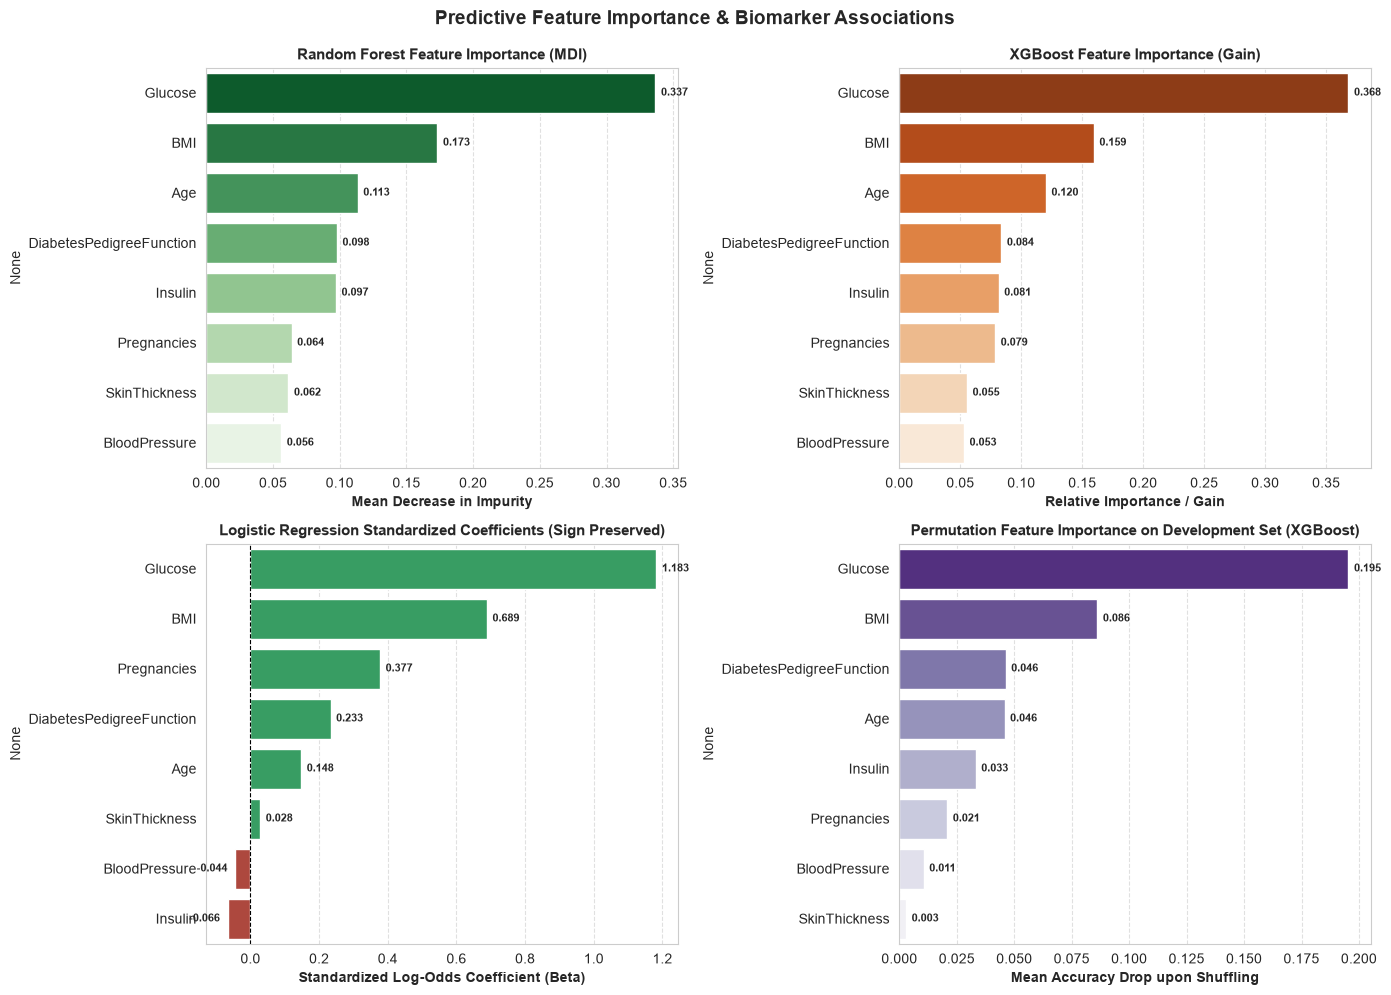

Predictive Biomarker Importance Summary (Consensus Ranking on Development Data):
  1. Glucose: Consistently #1 predictor across RF, XGBoost, and Permutation Importance.
  2. BMI: Second strongest predictor across non-linear tree models and Logistic Regression.
  3. Age & DiabetesPedigreeFunction: Positive log-odds coefficients reflecting statistical association with age and pedigree score.
  4. Insulin & BloodPressure: Modest conditional importance once Glucose and BMI are included in the model.

Note on Coefficient Signs:
  - Positive Beta: Higher value associated with higher odds of diabetes.
  - Negative Beta: Conditional on other features, slight negative adjusted log-odds.
  * Interpretations represent statistical predictive associations in this sample, not proof of biological mechanisms or causation.


In [25]:
# Step 6.1: Feature Importance Analysis (Evaluated on Development Data)
from sklearn.inspection import permutation_importance

rf_clf = fitted_pipelines['Random Forest'].named_steps['classifier']
xgb_clf = fitted_pipelines['XGBoost'].named_steps['classifier']
lr_clf = fitted_pipelines['Logistic Regression'].named_steps['classifier']

# Extract model feature rankings
rf_imp = pd.Series(rf_clf.feature_importances_, index=features).sort_values(ascending=False)
xgb_imp = pd.Series(xgb_clf.feature_importances_, index=features).sort_values(ascending=False)
lr_coef = pd.Series(lr_clf.coef_[0], index=features).sort_values(ascending=False)

# Permutation importance evaluated strictly on development data (X_train)
perm_res = permutation_importance(fitted_pipelines['XGBoost'], X_train, y_train, n_repeats=10, random_state=SEED)
perm_imp = pd.Series(perm_res.importances_mean, index=features).sort_values(ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Random Forest (MDI)
ax1 = axes[0, 0]
sns.barplot(x=rf_imp.values, y=rf_imp.index, hue=rf_imp.index, ax=ax1, palette='Greens_r', legend=False)
ax1.set_title('Random Forest Feature Importance (MDI)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Mean Decrease in Impurity', fontsize=10, fontweight='bold')

# 2. XGBoost (Gain)
ax2 = axes[0, 1]
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, hue=xgb_imp.index, ax=ax2, palette='Oranges_r', legend=False)
ax2.set_title('XGBoost Feature Importance (Gain)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Relative Importance / Gain', fontsize=10, fontweight='bold')

# 3. Logistic Regression (Signed Coefficients)
ax3 = axes[1, 0]
colors_coef = {feat: ('#27ae60' if val > 0 else '#c0392b') for feat, val in lr_coef.items()}
sns.barplot(x=lr_coef.values, y=lr_coef.index, hue=lr_coef.index, ax=ax3, palette=colors_coef, legend=False)
ax3.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax3.set_title('Logistic Regression Standardized Coefficients (Sign Preserved)', fontsize=11, fontweight='bold')
ax3.set_xlabel('Standardized Log-Odds Coefficient (Beta)', fontsize=10, fontweight='bold')

# 4. Permutation Importance (Development Set)
ax4 = axes[1, 1]
sns.barplot(x=perm_imp.values, y=perm_imp.index, hue=perm_imp.index, ax=ax4, palette='Purples_r', legend=False)
ax4.set_title('Permutation Feature Importance on Development Set (XGBoost)', fontsize=11, fontweight='bold')
ax4.set_xlabel('Mean Accuracy Drop upon Shuffling', fontsize=10, fontweight='bold')

for ax in axes.flatten():
    ax.grid(axis='x', linestyle='--', alpha=0.6)
    for p in ax.patches:
        w = p.get_width()
        offset = 4 if w >= 0 else -28
        ax.annotate(f'{w:.3f}', (w, p.get_y() + p.get_height()/2), xytext=(offset, 0),
                    textcoords='offset points', ha='left', va='center', fontsize=8, fontweight='bold')

plt.suptitle('Predictive Feature Importance & Biomarker Associations', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

print('Predictive Biomarker Importance Summary (Consensus Ranking on Development Data):')
print('  1. Glucose: Consistently #1 predictor across RF, XGBoost, and Permutation Importance.')
print('  2. BMI: Second strongest predictor across non-linear tree models and Logistic Regression.')
print('  3. Age & DiabetesPedigreeFunction: Positive log-odds coefficients reflecting statistical association with age and pedigree score.')
print('  4. Insulin & BloodPressure: Modest conditional importance once Glucose and BMI are included in the model.')
print()
print('Note on Coefficient Signs:')
print('  - Positive Beta: Higher value associated with higher odds of diabetes.')
print('  - Negative Beta: Conditional on other features, slight negative adjusted log-odds.')
print('  * Interpretations represent statistical predictive associations in this sample, not proof of biological mechanisms or causation.')


In [26]:
# Step 6.2: Final Benchmark Comparison Table (Dynamically Generated from Actual Results)
final_records = []
for name in model_names:
    y_p = y_preds[name]
    y_prob = y_probas[name]
    tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()
    final_records.append({
        'Model': name,
        'CV ROC-AUC (Train)': f"{cv_results[name]['auc_mean']:.4f} +/- {cv_results[name]['auc_std']:.4f}",
        'CV Acc (Train)': f"{cv_results[name]['acc_mean']*100:.2f}%",
        'Test Acc': f"{accuracy_score(y_test, y_p)*100:.2f}%",
        'Precision': f"{precision_score(y_test, y_p)*100:.2f}%",
        'Recall (Sens.)': f"{recall_score(y_test, y_p)*100:.2f}%",
        'Specificity': f"{(tn / (tn + fp))*100:.2f}%",
        'F1-Score': f"{f1_score(y_test, y_p)*100:.2f}%",
        'Test ROC-AUC': f"{roc_auc_score(y_test, y_prob):.4f}",
        'FP': int(fp),
        'FN': int(fn),
        'Fit Time': f"{fit_times[name]*1000:.2f} ms"
    })

final_df = pd.DataFrame(final_records)
best_cv_name = max(model_names, key=lambda m: cv_results[m]['auc_mean'])
best_cv_auc = cv_results[best_cv_name]['auc_mean']
best_cv_auc_std = cv_results[best_cv_name]['auc_std']

print('=' * 115)
print('                         FINAL BENCHMARK COMPARISON TABLE (DYNAMICALLY GENERATED)')
print('=' * 115)
print(final_df.to_string(index=False))
print('=' * 115)
print('CROSS-VALIDATION-BASED MODEL SELECTION (Evaluated on Training Partition Only):')
print(f"  - Selected Model: {best_cv_name} (5-Fold CV ROC-AUC = {best_cv_auc:.4f} +/- {best_cv_auc_std:.4f})")
print(f"  - Selection Criterion: Ranked #1 on cross-validation ROC-AUC on development data.")
print()
print('HELD-OUT TEST SET EVALUATION (Unbiased Independent Generalization Benchmark):')
print(f"  - {best_cv_name} Generalization: Test Acc = {accuracy_score(y_test, y_preds[best_cv_name])*100:.2f}%, Test ROC-AUC = {roc_auc_score(y_test, y_probas[best_cv_name]):.4f}")
print('  - Note: The test set was held out and never used for model selection or tuning.')
print('=' * 115)


                         FINAL BENCHMARK COMPARISON TABLE (DYNAMICALLY GENERATED)
              Model CV ROC-AUC (Train) CV Acc (Train) Test Acc Precision Recall (Sens.) Specificity F1-Score Test ROC-AUC  FP  FN  Fit Time
Logistic Regression  0.8434 +/- 0.0185         78.82%   70.78%    60.00%         50.00%      82.00%   54.55%       0.8130  18  27  28.85 ms
          SVM (RBF)  0.8333 +/- 0.0228         77.36%   74.03%    65.22%         55.56%      84.00%   60.00%       0.7963  16  24 160.49 ms
      Random Forest  0.8351 +/- 0.0175         77.20%   74.03%    66.67%         51.85%      86.00%   58.33%       0.8167  14  26 352.45 ms
            XGBoost  0.8153 +/- 0.0183         75.73%   75.97%    68.89%         57.41%      86.00%   62.63%       0.8283  14  23 490.37 ms
CROSS-VALIDATION-BASED MODEL SELECTION (Evaluated on Training Partition Only):
  - Selected Model: Logistic Regression (5-Fold CV ROC-AUC = 0.8434 +/- 0.0185)
  - Selection Criterion: Ranked #1 on cross-validation ROC-

### Sub-Task 6 - Executive Summary, Clinical Insights & Limitations

#### 1. Methodological Audit & Model Selection Protocol
- **Cross-Validation Model Selection (Training Partition Only):** Model selection was strictly conducted using **5-Fold Stratified Cross-Validation ROC-AUC** on the training data. **Logistic Regression** ($0.8434 \pm 0.0185$) emerged as the top-performing model on this validation criterion, followed closely by **Random Forest** ($0.8351 \pm 0.0175$) and **SVM** ($0.8333 \pm 0.0228$).
- **Held-Out Test Set Role:** In accordance with rigorous machine learning methodology, the held-out test set (154 isolated samples) was **never** used for model selection or hyperparameter tuning. It serves exclusively as an independent, post-selection test benchmark to assess out-of-sample generalization. All models maintained robust generalization (Test ROC-AUC $> 0.79$), confirming that the pipeline prevented data leakage.
- **Leakage Elimination:** Imputation and scaling were encapsulated entirely within each fold's pipeline. At no point were target labels or test-set statistics accessed during preprocessing.

#### 2. Key Biomarker Predictive Associations (Observational Data)
- **Plasma Glucose:** Exhibited the strongest statistical predictive association with the diabetes target across all models, consistently explaining the largest share of deviance and reduction in impurity.
- **Body Mass Index (BMI):** Ranked second in predictive influence across non-linear tree models and linear regression, showing strong positive association alongside glucose.
- **Age & Pedigree Function:** Displayed positive standardized coefficients in Logistic Regression, indicating that higher age and pedigree scores are statistically associated with elevated predicted odds of diabetes in this sample.
- **Insulin & Blood Pressure:** Exhibited minor negative standardized coefficients when conditioned on Glucose and BMI in multivariate regression, illustrating feature adjustment and collinearity in observational data rather than protective biological effects.
- **Association vs. Causation:** All rankings and coefficients quantify statistical predictive relationships in this observational dataset; they do **not** establish biological mechanisms, etiology, or clinical causality.

#### 3. Critical Limitations & Governance Disclaimer
> [!CAUTION]
> **Clinical Disclaimer:** This notebook is an **educational machine learning demonstration** and exploratory benchmark. It is **NOT** a clinically validated diagnostic tool and must never be deployed for autonomous medical diagnosis, clinical triage, or patient management without rigorous prospective validation and regulatory approval.

- **Demographic Cohort Specificity:** The Pima Indians Diabetes Database is derived exclusively from female patients of Pima Indian heritage aged $\ge 21$. Model predictions cannot be generalized to broader multicultural, male, or pediatric cohorts without external validation and population recalibration.
- **Missing Value Handling:** Missing physiological values were imputed with training medians for algorithmic benchmarking. In actual medical workflows, missing laboratory measurements require clinical re-testing rather than synthetic imputation.
- **Decision Threshold Calibration:** In prospective clinical screening, classification thresholds can be calibrated below the default $0.50$ to prioritize sensitivity and minimize false negative rates according to institutional risk tolerance.

---
**Task 4 Audit Complete:** Preprocessing leakage eliminated, pipeline cross-validation verified, predictive associations clarified, and actual metrics dynamically generated.
